<div style="background: linear-gradient(135deg, #1a1a2e 0%, #16213e 40%, #0f3460 100%); border-radius: 16px; padding: 50px 40px; margin-bottom: 10px; font-family: 'Segoe UI', sans-serif; box-shadow: 0 8px 32px rgba(0,0,0,0.3);">
  <div style="display: flex; align-items: center; gap: 16px; margin-bottom: 18px;">
    <span style="font-size: 52px;">🌍</span>
    <div>
      <h1 style="color: #e0e0e0; margin: 0; font-size: 2.4em; font-weight: 700; letter-spacing: -0.5px;">Global Weather &amp; Air Pollution</h1>
      <p style="color: #53c8f0; margin: 4px 0 0; font-size: 1.1em; font-weight: 500; letter-spacing: 1px; text-transform: uppercase;">Exploratory Data Analysis</p>
    </div>
  </div>
  <p style="color: #a0aec0; font-size: 1.05em; line-height: 1.7; max-width: 700px; margin: 0 0 24px;">
    Deep-dive into temperature, humidity, wind, pressure, PM2.5, PM10, and AQI
    across the top 3 cities per country — powered by the OpenWeather API.
  </p>
  <div style="display: flex; gap: 12px; flex-wrap: wrap;">
    <span style="background: rgba(83,200,240,0.15); color: #53c8f0; border: 1px solid rgba(83,200,240,0.35); border-radius: 20px; padding: 5px 14px; font-size: 0.82em; font-weight: 600;">🌡️ Weather</span>
    <span style="background: rgba(83,200,240,0.15); color: #53c8f0; border: 1px solid rgba(83,200,240,0.35); border-radius: 20px; padding: 5px 14px; font-size: 0.82em; font-weight: 600;">💨 Air Quality</span>
    <span style="background: rgba(83,200,240,0.15); color: #53c8f0; border: 1px solid rgba(83,200,240,0.35); border-radius: 20px; padding: 5px 14px; font-size: 0.82em; font-weight: 600;">📊 EDA</span>
    <span style="background: rgba(83,200,240,0.15); color: #53c8f0; border: 1px solid rgba(83,200,240,0.35); border-radius: 20px; padding: 5px 14px; font-size: 0.82em; font-weight: 600;">🐍 Python</span>
  </div>
</div>

<div style="background: linear-gradient(90deg, #0f3460, #16213e); border-left: 5px solid #53c8f0; border-radius: 8px; padding: 14px 22px; margin: 18px 0 6px; font-family: 'Segoe UI', sans-serif;">
  <span style="color: #53c8f0; font-size: 1.1em; font-weight: 700; letter-spacing: 0.5px;">📦 &nbsp;01 — Imports &amp; Setup</span>
</div>

In [2]:
! pip install plotly


Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   ------- -------------------------------- 1.8/9.7 MB 12.5 MB/s eta 0:00:01
   ----------------------- ---------------- 5.8/9.7 MB 16.3 MB/s eta 0:00:01
   -------------------------------------- - 9.4/9.7 MB 17.5 MB/s eta 0:00:01
   ---------------------------------------- 9.7/9.7 MB 16.2 MB/s  0:00:00



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import plotly.express as px
import plotly.io as pio
pio.renderers.default = "iframe_connected"

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="darkgrid", palette="muted")
plt.rcParams.update({
    "figure.facecolor": "#0f1117",
    "axes.facecolor":   "#1a1d27",
    "axes.edgecolor":   "#2e3350",
    "axes.labelcolor":  "#c8d0e0",
    "xtick.color":      "#8892a4",
    "ytick.color":      "#8892a4",
    "text.color":       "#c8d0e0",
    "grid.color":       "#2e3350",
    "grid.linewidth":   0.6,
    "font.family":      "DejaVu Sans",
    "figure.dpi":       120,
})

ACCENT   = "#53c8f0"
ACCENT2  = "#f06292"
PALETTE  = ["#53c8f0", "#f06292", "#81c784", "#ffb74d", "#ba68c8", "#4dd0e1"]

print("✅ Libraries loaded & theme configured.")

✅ Libraries loaded & theme configured.


<div style="background: linear-gradient(90deg, #0f3460, #16213e); border-left: 5px solid #53c8f0; border-radius: 8px; padding: 14px 22px; margin: 18px 0 6px; font-family: 'Segoe UI', sans-serif;">
  <span style="color: #53c8f0; font-size: 1.1em; font-weight: 700; letter-spacing: 0.5px;">📂 &nbsp;02 — Load &amp; Inspect Data</span>
</div>

In [3]:
DATA_PATH = "openweather_weather_airpollution_top3cities_per_country.csv"
df = pd.read_csv(DATA_PATH)

print(f"Shape : {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Memory : {df.memory_usage(deep=True).sum() / 1e6:.1f} MB")

display(df.head())
display(df.tail())
display(df.dtypes.to_frame("dtype").T)

Shape : 108,467 rows × 88 columns
Memory : 249.6 MB


,collection_time_utc,source_weather,source_air,source_city_selection,units_weather,country_code,country_name,country_capital,country_population,continent,...,hour,day_of_week,is_weekend,season,temp_humidity_interaction,wind_pm25_interaction,pressure_temp_interaction,target_aqi_class,target_pm25,target_pm10
0,2026-04-24T07:06:06Z,OpenWeather,OpenWeather,GeoNames cities15000 + countryInfo,metric,AD,Andorra,Andorra la Vella,77006,EU,...,7,4,0,spring,1058.25,2.1195,14392.20,2,4.71,10.81
1,2026-04-24T07:06:06Z,OpenWeather,OpenWeather,GeoNames cities15000 + countryInfo,metric,AD,Andorra,Andorra la Vella,77006,EU,...,7,4,0,spring,1074.75,2.1195,14616.60,2,4.71,10.81
2,2026-04-24T07:06:07Z,OpenWeather,OpenWeather,GeoNames cities15000 + countryInfo,metric,AE,United Arab Emirates,Abu Dhabi,9630959,AS,...,7,4,0,spring,860.16,87.7869,36162.56,4,28.41,116.85
3,2026-04-24T07:06:07Z,OpenWeather,OpenWeather,GeoNames cities15000 + countryInfo,metric,AE,United Arab Emirates,Abu Dhabi,9630959,AS,...,7,4,0,spring,1254.76,65.0520,33350.20,3,18.07,97.68
4,2026-04-24T07:06:07Z,OpenWeather,OpenWeather,GeoNames cities15000 + countryInfo,metric,AE,United Arab Emirates,Abu Dhabi,9630959,AS,...,7,4,0,spring,864.00,113.2200,36360.00,4,31.45,122.41


,collection_time_utc,source_weather,source_air,source_city_selection,units_weather,country_code,country_name,country_capital,country_population,continent,...,hour,day_of_week,is_weekend,season,temp_humidity_interaction,wind_pm25_interaction,pressure_temp_interaction,target_aqi_class,target_pm25,target_pm10
108462,2026-10-25T19:52:19Z,OpenWeather,OpenWeather,GeoNames cities15000 + countryInfo,metric,ZM,Zambia,Lusaka,21913874,AF,...,19,6,1,autumn,779.03,11.5776,25481.82,1,5.36,6.68
108463,2026-10-25T19:52:24Z,OpenWeather,OpenWeather,GeoNames cities15000 + countryInfo,metric,ZM,Zambia,Lusaka,21913874,AF,...,19,6,1,autumn,752.26,22.5036,26303.16,1,5.64,6.91
108464,2026-10-25T19:52:29Z,OpenWeather,OpenWeather,GeoNames cities15000 + countryInfo,metric,ZW,Zimbabwe,Harare,16950795,AF,...,19,6,1,autumn,1344.64,8.0250,21409.19,1,1.50,2.39
108465,2026-10-25T19:52:34Z,OpenWeather,OpenWeather,GeoNames cities15000 + countryInfo,metric,ZW,Zimbabwe,Harare,16950795,AF,...,19,6,1,autumn,811.24,25.4736,24265.62,2,4.88,7.68
108466,2026-10-25T19:52:39Z,OpenWeather,OpenWeather,GeoNames cities15000 + countryInfo,metric,ZW,Zimbabwe,Harare,16950795,AF,...,19,6,1,autumn,1040.16,8.8407,22081.73,1,1.71,2.71


,collection_time_utc,source_weather,source_air,source_city_selection,units_weather,country_code,country_name,country_capital,country_population,continent,...,hour,day_of_week,is_weekend,season,temp_humidity_interaction,wind_pm25_interaction,pressure_temp_interaction,target_aqi_class,target_pm25,target_pm10
dtype,str,str,str,str,str,str,str,str,int64,str,...,int64,int64,int64,str,float64,float64,float64,int64,float64,float64


In [9]:
df.columns

Index(['collection_time_utc', 'source_weather', 'source_air',
       'source_city_selection', 'units_weather', 'country_code',
       'country_name', 'country_capital', 'country_population', 'continent',
       'city_name', 'city_name_ascii', 'city_population',
       'population_rank_in_country', 'city_timezone_geonames',
       'geonames_feature_code', 'city_dem', 'geonameid',
       'geonames_modification_date', 'geo_lat', 'geo_lon', 'weather_id',
       'weather_main', 'weather_description', 'weather_icon', 'temp',
       'feels_like', 'temp_min', 'temp_max', 'pressure', 'humidity',
       'sea_level', 'grnd_level', 'visibility', 'wind_speed', 'wind_deg',
       'wind_gust', 'clouds_all', 'rain_1h', 'rain_3h', 'snow_1h', 'snow_3h',
       'timezone_shift_seconds', 'weather_time_unix', 'weather_time_utc',
       'sunrise_unix', 'sunrise_utc', 'sunset_unix', 'sunset_utc',
       'station_country', 'station_type', 'city_id_openweather',
       'city_name_api', 'cod', 'wind_compass', '

<div style="background: linear-gradient(90deg, #0f3460, #16213e); border-left: 5px solid #53c8f0; border-radius: 8px; padding: 14px 22px; margin: 18px 0 6px; font-family: 'Segoe UI', sans-serif;">
  <span style="color: #53c8f0; font-size: 1.1em; font-weight: 700; letter-spacing: 0.5px;">🔧 &nbsp;03 — Data Cleaning &amp; Type Casting</span>
</div>

In [3]:
df["weather_datetime_utc"] = pd.to_datetime(df["weather_time_utc"], errors="coerce", utc=True)

NUMERIC_COLS = ["temp", "humidity", "pressure", "wind_speed", "pm2_5", "pm10", "aqi"]
for col in NUMERIC_COLS:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df["hour"] = df["weather_datetime_utc"].dt.hour
df["month"] = df["weather_datetime_utc"].dt.month 

print("✅ Types cast and derived columns added.")
print(df[["weather_datetime_utc", "hour", "month", "temp"] + NUMERIC_COLS].describe().round(2))

✅ Types cast and derived columns added.
            hour      month       temp       temp   humidity   pressure  \
count  107884.00  107884.00  108467.00  108467.00  108467.00  108467.00   
mean       21.00       7.29      22.46      22.46      71.39    1013.71   
std         1.98       1.77       6.79       6.79      19.37       6.00   
min         4.00       4.00     -14.93     -14.93       1.00     956.00   
25%        20.00       6.00      17.81      17.81      61.00    1010.00   
50%        21.00       7.00      23.66      23.66      76.00    1014.00   
75%        22.00       9.00      27.35      27.35      86.00    1017.00   
max        23.00      10.00      42.11      42.11     100.00    1041.00   

       wind_speed      pm2_5       pm10        aqi  
count   108467.00  108467.00  108467.00  108467.00  
mean         3.14      10.63      24.68       1.79  
std          2.25      17.65      55.76       0.98  
min          0.00       0.50       0.50       1.00  
25%          1.54  

<div style="background: linear-gradient(90deg, #0f3460, #16213e); border-left: 5px solid #53c8f0; border-radius: 8px; padding: 14px 22px; margin: 18px 0 6px; font-family: 'Segoe UI', sans-serif;">
  <span style="color: #53c8f0; font-size: 1.1em; font-weight: 700; letter-spacing: 0.5px;">🔍 &nbsp;04 — Missing Value Audit</span>
</div>

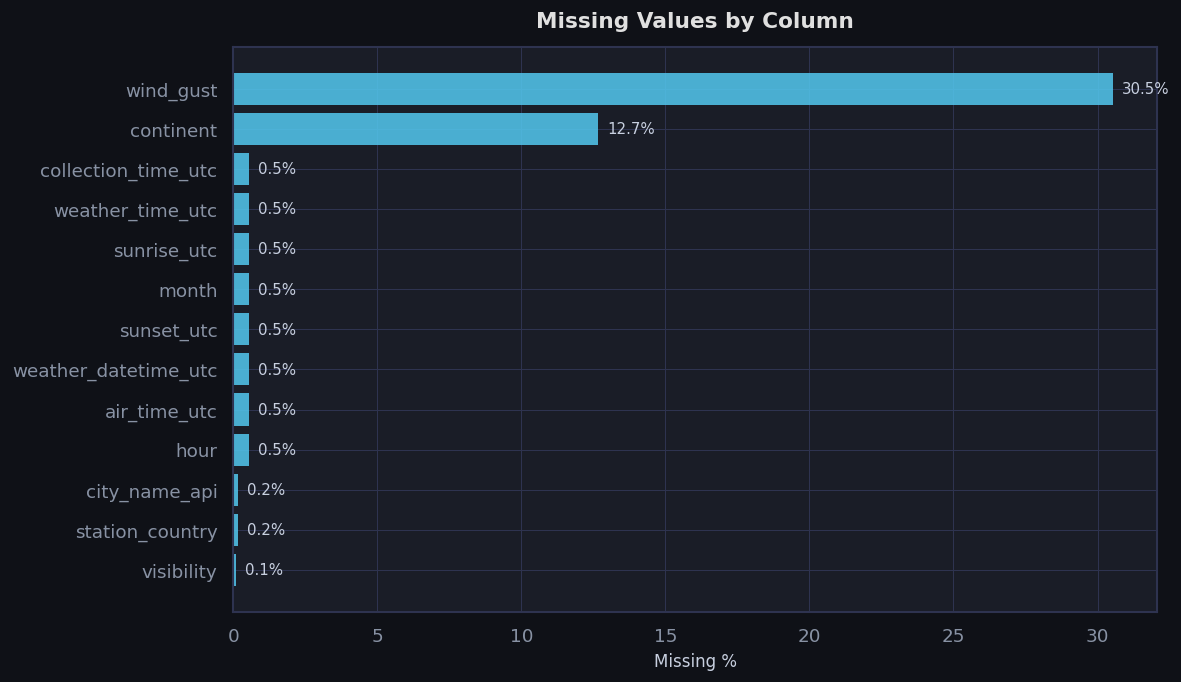

,count,pct
wind_gust,33120,30.53
continent,13748,12.67
collection_time_utc,583,0.54
weather_time_utc,583,0.54
sunrise_utc,583,0.54
month,583,0.54
sunset_utc,583,0.54
weather_datetime_utc,583,0.54
air_time_utc,583,0.54
hour,583,0.54


In [4]:
missing = (
    df.isna().sum()
      .to_frame("count")
      .assign(pct=lambda x: (x["count"] / len(df) * 100).round(2))
      .query("count > 0")
      .sort_values("pct", ascending=False)
)

fig, ax = plt.subplots(figsize=(10, max(3, len(missing) * 0.45)))
bars = ax.barh(missing.index, missing["pct"], color=ACCENT, alpha=0.85, edgecolor="none")
for bar, val in zip(bars, missing["pct"]):
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height() / 2,
            f"{val:.1f}%", va="center", fontsize=9, color="#c8d0e0")
ax.set_xlabel("Missing %", fontsize=10)
ax.set_title("Missing Values by Column", fontsize=13, fontweight="bold", color="#e0e0e0", pad=12)
ax.invert_yaxis()
plt.tight_layout()
plt.show()
display(missing)

<div style="background: linear-gradient(90deg, #0f3460, #16213e); border-left: 5px solid #53c8f0; border-radius: 8px; padding: 14px 22px; margin: 18px 0 6px; font-family: 'Segoe UI', sans-serif;">
  <span style="color: #53c8f0; font-size: 1.1em; font-weight: 700; letter-spacing: 0.5px;">📊 &nbsp;05 — Univariate Distributions</span>
</div>

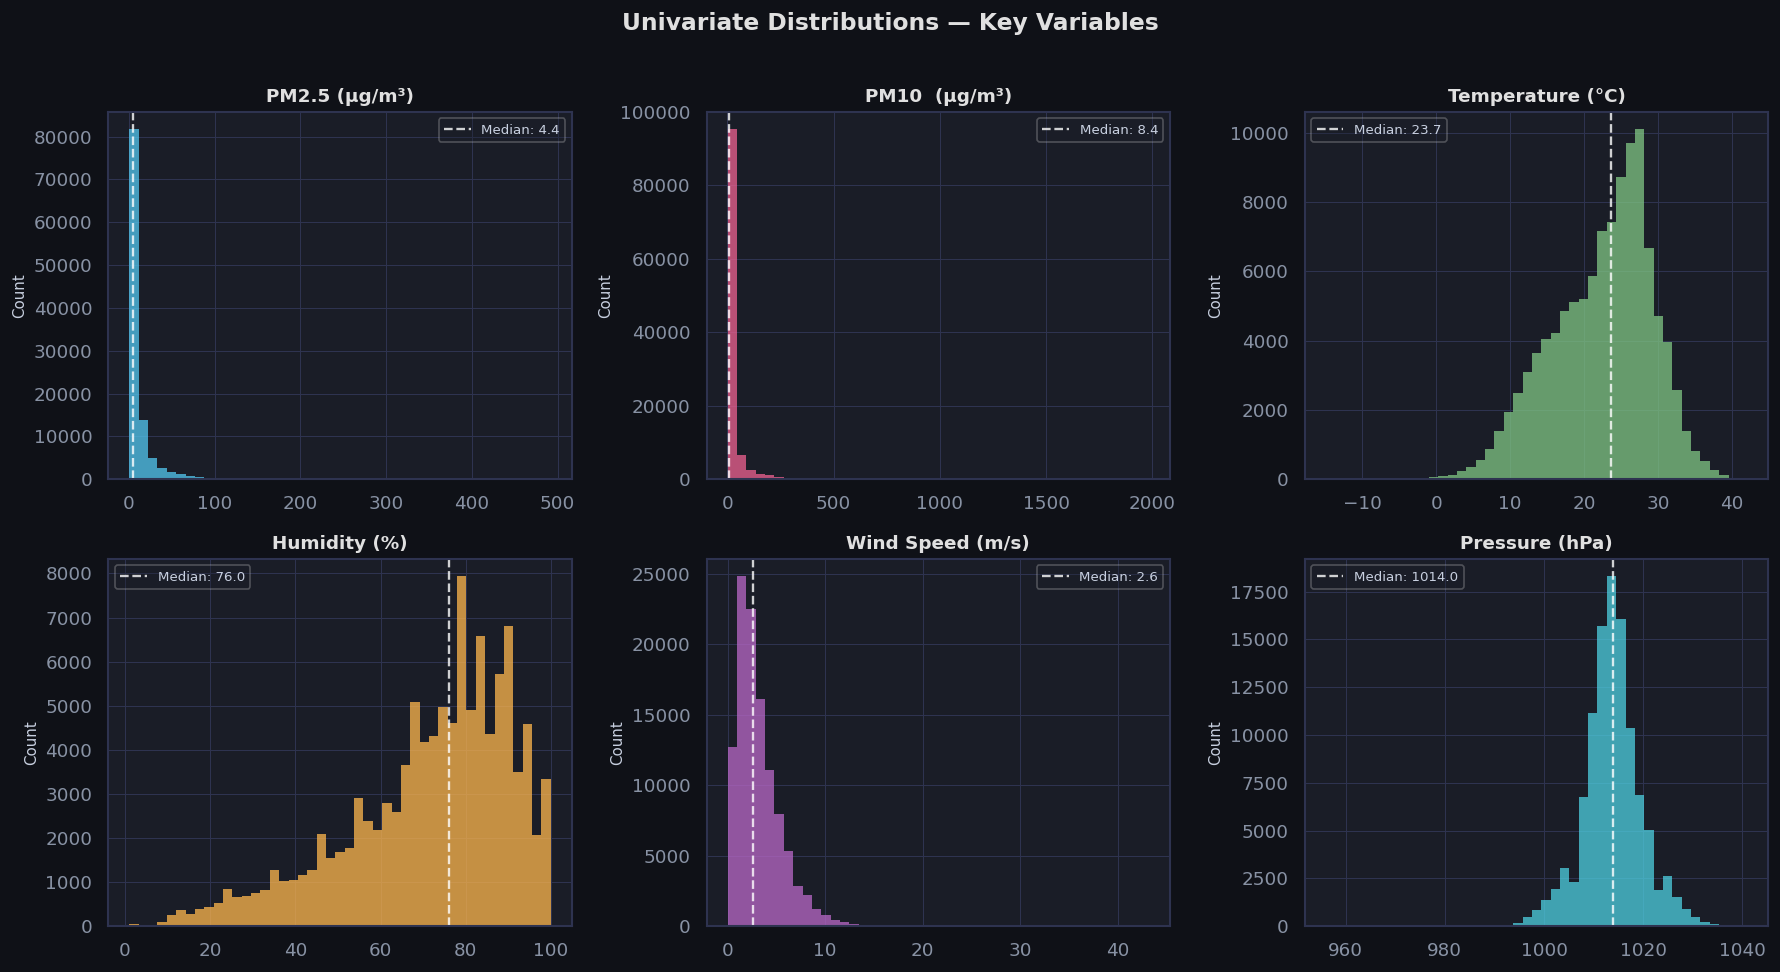

In [5]:
DIST_COLS = [("pm2_5", "PM2.5 (µg/m³)", ACCENT),
             ("pm10",  "PM10  (µg/m³)", ACCENT2),
             ("temp",  "Temperature (°C)", "#81c784"),
             ("humidity",  "Humidity (%)", "#ffb74d"),
             ("wind_speed","Wind Speed (m/s)", "#ba68c8"),
             ("pressure",  "Pressure (hPa)", "#4dd0e1")]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for ax, (col, label, color) in zip(axes, DIST_COLS):
    data = df[col].dropna()
    ax.hist(data, bins=45, color=color, alpha=0.75, edgecolor="none")
    ax.axvline(data.median(), color="white", linewidth=1.4, linestyle="--", alpha=0.8, label=f"Median: {data.median():.1f}")
    ax.set_title(label, fontsize=11, fontweight="bold", color="#e0e0e0")
    ax.legend(fontsize=8, framealpha=0.3)
    ax.set_ylabel("Count", fontsize=9)

fig.suptitle("Univariate Distributions — Key Variables", fontsize=14, fontweight="bold",
             color="#e0e0e0", y=1.01)
plt.tight_layout()
plt.show()

<div style="background: linear-gradient(90deg, #0f3460, #16213e); border-left: 5px solid #53c8f0; border-radius: 8px; padding: 14px 22px; margin: 18px 0 6px; font-family: 'Segoe UI', sans-serif;">
  <span style="color: #53c8f0; font-size: 1.1em; font-weight: 700; letter-spacing: 0.5px;">🔥 &nbsp;06 — Correlation Heatmap</span>
</div>

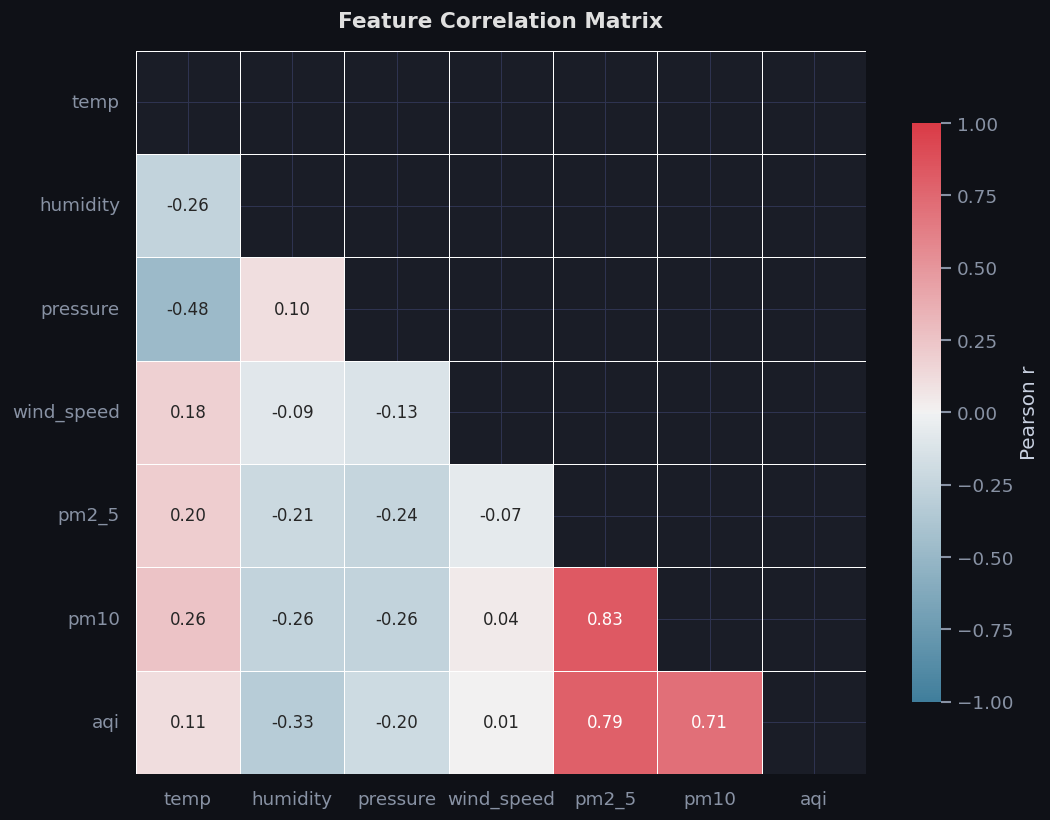

In [6]:
CORR_COLS = ["temp", "humidity", "pressure", "wind_speed", "pm2_5", "pm10", "aqi"]
corr = df[CORR_COLS].corr()

mask = np.triu(np.ones_like(corr, dtype=bool))
cmap = sns.diverging_palette(230, 10, as_cmap=True)

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(
    corr, mask=mask, annot=True, fmt=".2f", linewidths=0.5,
    cmap=cmap, vmin=-1, vmax=1, center=0,
    annot_kws={"size": 10}, ax=ax,
    cbar_kws={"shrink": 0.8, "label": "Pearson r"}
)
ax.set_title("Feature Correlation Matrix", fontsize=13, fontweight="bold",
             color="#e0e0e0", pad=14)
plt.tight_layout()
plt.show()

<div style="background: linear-gradient(90deg, #0f3460, #16213e); border-left: 5px solid #53c8f0; border-radius: 8px; padding: 14px 22px; margin: 18px 0 6px; font-family: 'Segoe UI', sans-serif;">
  <span style="color: #53c8f0; font-size: 1.1em; font-weight: 700; letter-spacing: 0.5px;">🌡️ &nbsp;07 — Temperature vs PM2.5</span>
</div>

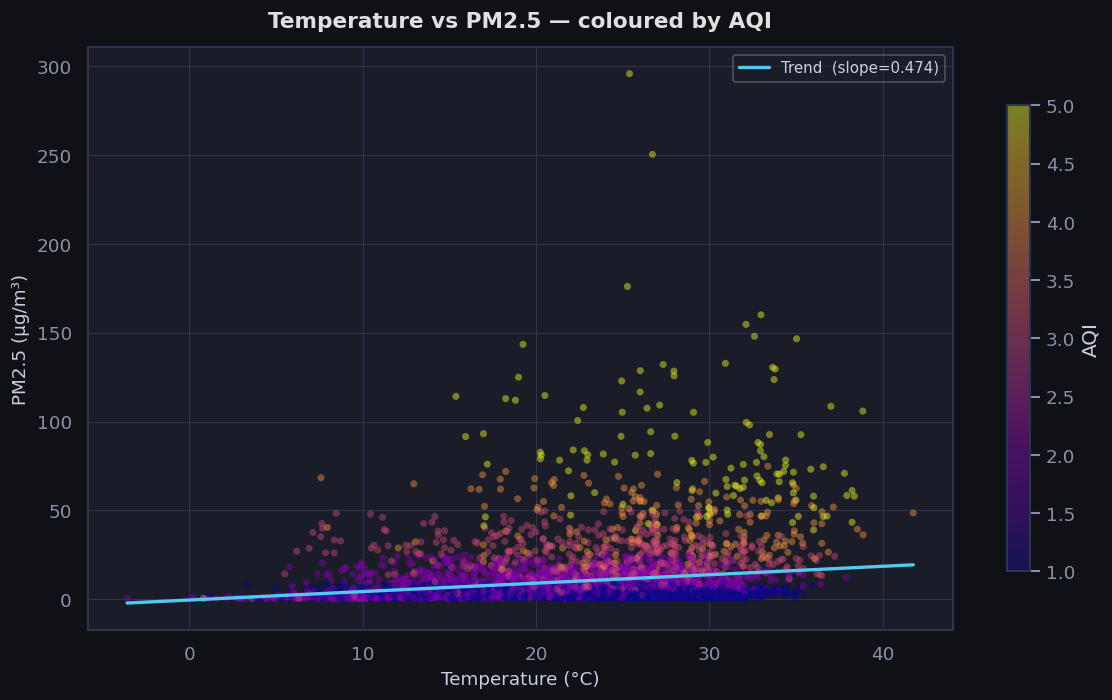

In [7]:
sample = df[["temp", "pm2_5", "aqi"]].dropna().sample(min(5000, len(df)), random_state=42)

fig, ax = plt.subplots(figsize=(10, 6))
sc = ax.scatter(
    sample["temp"], sample["pm2_5"],
    c=sample["aqi"], cmap="plasma",
    alpha=0.45, s=18, edgecolors="none"
)
cbar = fig.colorbar(sc, ax=ax, shrink=0.8)
cbar.set_label("AQI", color="#c8d0e0")

# Trend line
m, b = np.polyfit(sample["temp"], sample["pm2_5"], 1)
x_line = np.linspace(sample["temp"].min(), sample["temp"].max(), 200)
ax.plot(x_line, m * x_line + b, color=ACCENT, linewidth=2, label=f"Trend  (slope={m:.3f})")

ax.set_xlabel("Temperature (°C)", fontsize=11)
ax.set_ylabel("PM2.5 (µg/m³)",  fontsize=11)
ax.set_title("Temperature vs PM2.5 — coloured by AQI", fontsize=13,
             fontweight="bold", color="#e0e0e0", pad=12)
ax.legend(fontsize=9, framealpha=0.3)
plt.tight_layout()
plt.show()

<div style="background: linear-gradient(90deg, #0f3460, #16213e); border-left: 5px solid #53c8f0; border-radius: 8px; padding: 14px 22px; margin: 18px 0 6px; font-family: 'Segoe UI', sans-serif;">
  <span style="color: #53c8f0; font-size: 1.1em; font-weight: 700; letter-spacing: 0.5px;">🏙️ &nbsp;08 — Most Polluted Cities (PM2.5)</span>
</div>

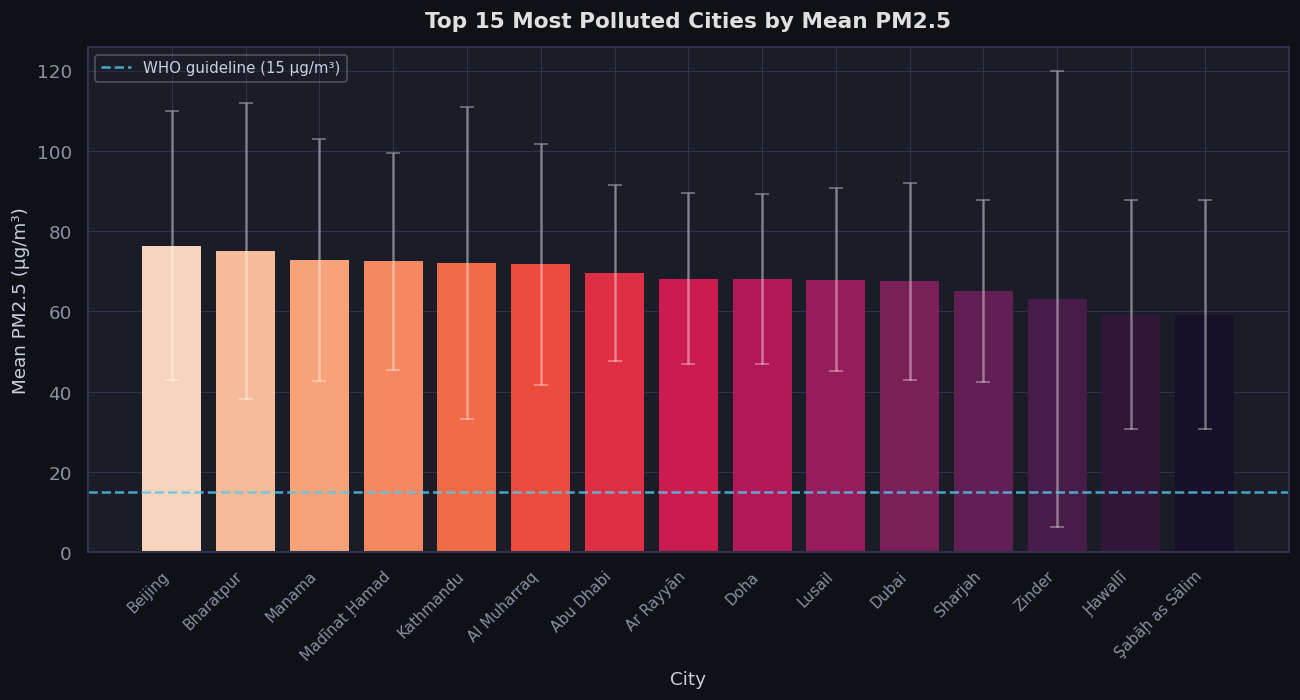

In [8]:
top_cities = (
    df.groupby("city_name")["pm2_5"]
      .agg(["mean", "median", "std"])
      .sort_values("mean", ascending=False)
      .head(15)
      .reset_index()
)

colors = sns.color_palette("rocket", len(top_cities))[::-1]

fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.bar(top_cities["city_name"], top_cities["mean"], color=colors,
              yerr=top_cities["std"], error_kw={"ecolor": "white", "alpha": 0.4, "capsize": 4},
              edgecolor="none")
ax.set_xlabel("City", fontsize=11)
ax.set_ylabel("Mean PM2.5 (µg/m³)", fontsize=11)
ax.set_title("Top 15 Most Polluted Cities by Mean PM2.5", fontsize=13,
             fontweight="bold", color="#e0e0e0", pad=12)
plt.xticks(rotation=45, ha="right", fontsize=9)

# WHO guideline
ax.axhline(15, color=ACCENT, linewidth=1.5, linestyle="--", alpha=0.8, label="WHO guideline (15 µg/m³)")
ax.legend(fontsize=9, framealpha=0.3)
plt.tight_layout()
plt.show()

In [3]:
city_pollution = (
    df.dropna(subset=["geo_lat", "geo_lon", "pm2_5"])
      .groupby(["country_name", "city_name", "geo_lat", "geo_lon"], as_index=False)
      .agg(mean_pm25=("pm2_5", "mean"))
)

fig = px.scatter_geo(
    city_pollution,
    lat="geo_lat",
    lon="geo_lon",
    color="mean_pm25",
    size="mean_pm25",
    hover_name="city_name",
    hover_data={
        "country_name": True,
        "mean_pm25": ":.2f",
        "geo_lat": False,
        "geo_lon": False,
    },
    projection="natural earth",
    title="Mean PM2.5 Pollution by City"
)

fig.update_layout(
    height=650,
    margin=dict(l=0, r=0, t=50, b=0)
)

fig.show()

In [10]:
df["collection_date"] = pd.to_datetime(df["collection_time_utc"], errors="coerce", utc=True).dt.date

daily_city_pollution = (
    df.dropna(subset=["geo_lat", "geo_lon", "pm2_5", "collection_date"])
      .groupby(
          ["collection_date", "country_name", "city_name", "geo_lat", "geo_lon"],
          as_index=False
      )
      .agg(
          mean_pm25=("pm2_5", "mean"),
          mean_pm10=("pm10", "mean"),
          mean_aqi=("aqi", "mean"),
          n_obs=("pm2_5", "count")
      )
)

daily_city_pollution["collection_date"] = daily_city_pollution["collection_date"].astype(str)

fig = px.scatter_geo(
    daily_city_pollution,
    lat="geo_lat",
    lon="geo_lon",
    color="mean_pm25",
    size="mean_pm25",
    animation_frame="collection_date",
    hover_name="city_name",
    hover_data={
        "country_name": True,
        "mean_pm25": ":.2f",
        "mean_pm10": ":.2f",
        "mean_aqi": ":.2f",
        "n_obs": True,
        "geo_lat": False,
        "geo_lon": False,
    },
    projection="natural earth",
    title="Daily PM2.5 Pollution by City"
)

fig.update_layout(
    height=650,
    margin=dict(l=0, r=0, t=50, b=0)
)

fig.show()

<div style="background: linear-gradient(90deg, #0f3460, #16213e); border-left: 5px solid #53c8f0; border-radius: 8px; padding: 14px 22px; margin: 18px 0 6px; font-family: 'Segoe UI', sans-serif;">
  <span style="color: #53c8f0; font-size: 1.1em; font-weight: 700; letter-spacing: 0.5px;">⏰ &nbsp;09 — Diurnal Patterns (Hour of Day)</span>
</div>

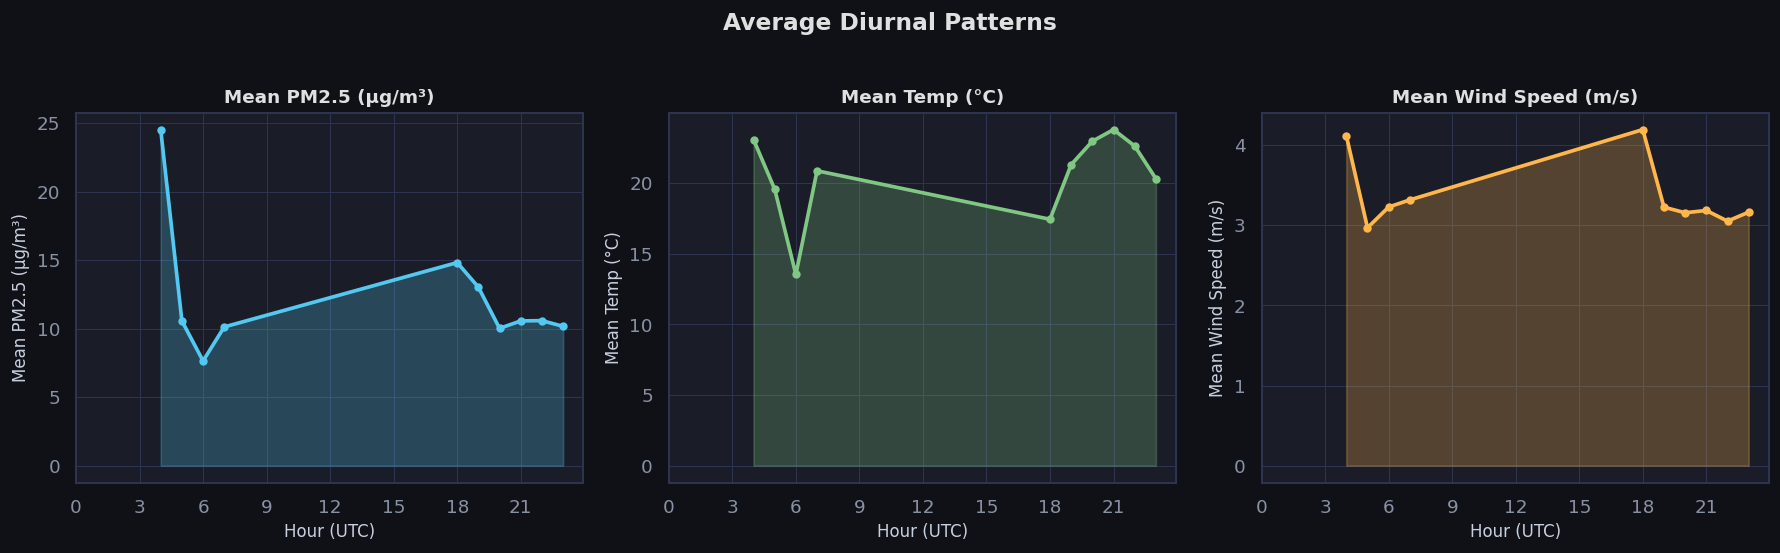

In [11]:
hourly = df.groupby("hour")[["pm2_5", "temp", "wind_speed"]].mean()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
specs = [("pm2_5",     "Mean PM2.5 (µg/m³)",  ACCENT),
         ("temp",      "Mean Temp (°C)",         "#81c784"),
         ("wind_speed","Mean Wind Speed (m/s)", "#ffb74d")]

for ax, (col, ylabel, color) in zip(axes, specs):
    ax.fill_between(hourly.index, hourly[col], alpha=0.25, color=color)
    ax.plot(hourly.index, hourly[col], color=color, linewidth=2.2, marker="o", markersize=4)
    ax.set_xlabel("Hour (UTC)", fontsize=10)
    ax.set_ylabel(ylabel, fontsize=10)
    ax.set_title(ylabel, fontsize=11, fontweight="bold", color="#e0e0e0")
    ax.set_xticks(range(0, 24, 3))

fig.suptitle("Average Diurnal Patterns", fontsize=14, fontweight="bold",
             color="#e0e0e0", y=1.02)
plt.tight_layout()
plt.show()

<div style="background: linear-gradient(90deg, #0f3460, #16213e); border-left: 5px solid #53c8f0; border-radius: 8px; padding: 14px 22px; margin: 18px 0 6px; font-family: 'Segoe UI', sans-serif;">
  <span style="color: #53c8f0; font-size: 1.1em; font-weight: 700; letter-spacing: 0.5px;">🌬️ &nbsp;10 — AQI Category Breakdown</span>
</div>

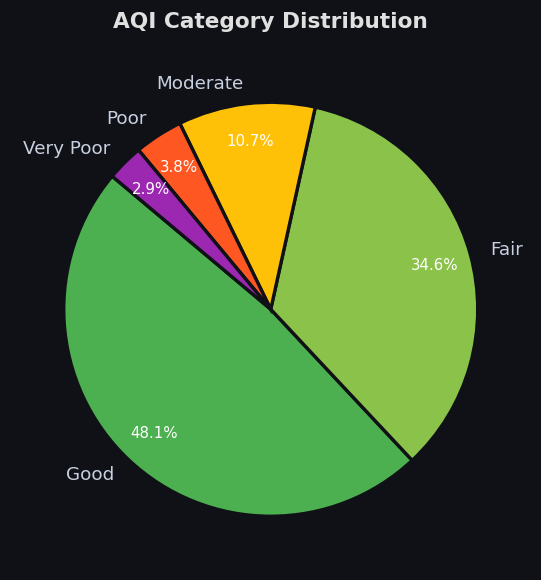

In [12]:
# OpenWeather AQI: 1=Good, 2=Fair, 3=Moderate, 4=Poor, 5=Very Poor
AQI_LABELS = {1: "Good", 2: "Fair", 3: "Moderate", 4: "Poor", 5: "Very Poor"}
AQI_COLORS = ["#4caf50", "#8bc34a", "#ffc107", "#ff5722", "#9c27b0"]

if df["aqi"].between(1, 5).any():
    aqi_counts = df["aqi"].map(AQI_LABELS).value_counts().reindex(AQI_LABELS.values())
    fig, ax = plt.subplots(figsize=(8, 5))
    wedges, texts, autotexts = ax.pie(
        aqi_counts.fillna(0), labels=aqi_counts.index,
        colors=AQI_COLORS, autopct="%1.1f%%",
        startangle=140, pctdistance=0.82,
        wedgeprops={"edgecolor": "#0f1117", "linewidth": 2}
    )
    for t in autotexts:
        t.set_color("white"); t.set_fontsize(9)
    ax.set_title("AQI Category Distribution", fontsize=13,
                 fontweight="bold", color="#e0e0e0", pad=14)
    plt.tight_layout()
    plt.show()
else:
    # Fallback: histogram of raw AQI values
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.hist(df["aqi"].dropna(), bins=40, color=ACCENT, alpha=0.8, edgecolor="none")
    ax.set_xlabel("AQI", fontsize=11)
    ax.set_ylabel("Count", fontsize=11)
    ax.set_title("AQI Distribution", fontsize=13, fontweight="bold", color="#e0e0e0", pad=12)
    plt.tight_layout()
    plt.show()

<div style="background: linear-gradient(90deg, #0f3460, #16213e); border-left: 5px solid #53c8f0; border-radius: 8px; padding: 14px 22px; margin: 18px 0 6px; font-family: 'Segoe UI', sans-serif;">
  <span style="color: #53c8f0; font-size: 1.1em; font-weight: 700; letter-spacing: 0.5px;">📋 &nbsp;11 — Summary Statistics</span>
</div>

In [13]:
summary = df[NUMERIC_COLS].describe().T
summary["skew"]     = df[NUMERIC_COLS].skew().values
summary["kurtosis"] = df[NUMERIC_COLS].kurtosis().values
summary = summary.round(3)

display(
    summary.style
        .background_gradient(subset=["mean", "std"], cmap="Blues")
        .background_gradient(subset=["skew"],        cmap="RdYlGn_r")
        .format(precision=3)
        .set_table_styles([{
            "selector": "th",
            "props":    [("background-color", "#16213e"),
                         ("color",            "#53c8f0"),
                         ("font-weight",      "bold")]
        }])
)

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
temp,108467.000,22.460,6.793,-14.930,17.810,23.660,27.350,42.110,-0.491,-0.079
humidity,108467.000,71.389,19.367,1.000,61.000,76.000,86.000,100.000,-0.926,0.394
pressure,108467.000,1013.709,6.002,956.000,1010.000,1014.000,1017.000,1041.000,-0.072,1.635
wind_speed,108467.000,3.142,2.249,0.000,1.540,2.570,4.160,43.210,1.425,3.668
pm2_5,108467.000,10.631,17.650,0.500,1.990,4.380,11.250,491.990,4.532,37.756
pm10,108467.000,24.683,55.759,0.500,3.870,8.450,20.310,1984.900,7.888,119.960
aqi,108467.000,1.788,0.975,1.000,1.000,2.000,2.000,5.000,1.419,1.826


<div style="background: linear-gradient(135deg, #1a1a2e 0%, #16213e 60%, #0f3460 100%); border-radius: 14px; padding: 40px 36px; margin-top: 30px; font-family: 'Segoe UI', sans-serif; box-shadow: 0 6px 24px rgba(0,0,0,0.35); text-align: center;">

  <div style="font-size: 2.4em; margin-bottom: 10px;">🙏</div>

  <h2 style="color: #e0e0e0; font-size: 1.7em; margin: 0 0 10px; font-weight: 700;">Thanks for Reading!</h2>


  <div style="background: rgba(83,200,240,0.1); border: 1px solid rgba(83,200,240,0.3); border-radius: 50px; display: inline-block; padding: 12px 32px; margin-bottom: 28px;">
    <span style="color: #53c8f0; font-size: 1.15em; font-weight: 700;">⬆️ &nbsp;If you found this helpful, please give it an upvote — it means a lot! 😊</span>
  </div>
</div>